# Predicción de incumplimiento de pago de tarjeta de crédito

**Problema de negocio:** un banco necesita anticipar qué clientes tienen alta probabilidad de
**incumplir el pago de su tarjeta de crédito**, para ajustar límites de crédito, tasas de interés,
o negar la emisión de nuevas tarjetas. Esto es un problema clásico de **scoring crediticio /
credit risk modeling**, formulado como **clasificación binaria supervisada**.

**Variable objetivo:** `incumplimiento_tarjeta_credito` (Sí = el cliente incumplió, No = el cliente pagó normalmente).

## 1. Importación de librerías

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score
)
import shap
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 422  
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Carga de datos
**archivo de daos:**
1. los datos pertenecen al portal kaggle

In [13]:

# Cargamos el datos
df = pd.read_csv("clientes_credito_limpios.csv")

print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()


Dimensiones del dataset: 45528 filas x 19 columnas


,id_cliente,nombre,edad,genero,tiene_auto,tiene_casa,numero_hijos,ingreso_anual_neto,dias_empleado,tipo_ocupacion,total_miembros_familia,trabajador_migrante,pagos_anuales_deuda,limite_credito,porcentaje_limite_credito_utilizado,puntaje_crediticio,incumplimientos_previos,incumplimiento_ultimos_6_meses,incumplimiento_tarjeta_credito
0,CST_115179,Ita Bose,46,Femenino,No,Sí,0,107934.04,612,Desconocido,1,Sí,33070.28,18690.93,73,544,2,Sí,Sí
1,CST_121920,Alper Jonathan,29,Masculino,No,Sí,0,109862.62,2771,Obreros,2,No,15329.53,37745.19,52,857,0,No,No
2,CST_109330,Umesh Desai,37,Masculino,No,Sí,0,230153.17,204,Obreros,2,No,48416.60,41598.36,43,650,0,No,No
3,CST_128288,Rie,39,Femenino,No,Sí,0,122325.82,11941,Personal administrativo,2,No,22574.36,32627.76,20,754,0,No,No
4,CST_151355,Mccool,46,Masculino,Sí,Sí,0,387286.00,1459,Personal administrativo,1,No,38282.95,52950.64,75,927,0,No,No


In [14]:
#
info_df = pd.DataFrame({
    "dtype": df.dtypes,
    "nulos": df.isnull().sum(),
    "% nulos": (df.isnull().mean() * 100).round(2),
    "valores_unicos": df.nunique()
})
info_df


,dtype,nulos,% nulos,valores_unicos
id_cliente,object,0,0.0,45528
nombre,object,0,0.0,3991
edad,int64,0,0.0,33
genero,object,0,0.0,3
tiene_auto,object,0,0.0,3
tiene_casa,object,0,0.0,2
numero_hijos,int64,0,0.0,10
ingreso_anual_neto,float64,0,0.0,45502
dias_empleado,int64,0,0.0,7861
tipo_ocupacion,object,0,0.0,19


In [15]:

print("Filas duplicadas:", df.duplicated().sum())
print("id_cliente duplicados:", df['id_cliente'].duplicated().sum())


Filas duplicadas: 0
id_cliente duplicados: 0


## 3. Análisis Exploratorio de Datos

C:\Users\Usuario\AppData\Local\Temp\ipykernel_1832\2201479019.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='incumplimiento_tarjeta_credito',


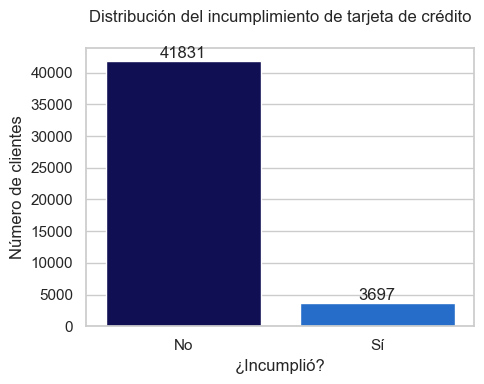

In [16]:



fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='incumplimiento_tarjeta_credito',
              order=['No', 'Sí'], palette=["#05045EB0", "#0B69E4"], ax=ax)
ax.set_title("Distribución del incumplimiento de tarjeta de crédito\n")
ax.set_xlabel("¿Incumplió?")
ax.set_ylabel("Número de clientes")
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.show()


**Observación:** solo ~8.1% de los clientes incumplió el pago de su tarjeta, por lo que los datos estan desbalaceados.

### 3.1 Variables numéricas: distribución y atipicos

In [17]:

num_cols = ['edad', 'numero_hijos', 'ingreso_anual_neto', 'dias_empleado',
            'total_miembros_familia', 'pagos_anuales_deuda', 'limite_credito',
            'porcentaje_limite_credito_utilizado', 'puntaje_crediticio',
            'incumplimientos_previos']

df[num_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
edad,45528.0,38.993411,9.543990,23.00,31.0000,39.000,47.0000,5.500000e+01
numero_hijos,45528.0,0.413504,0.719972,0.00,0.0000,0.000,1.0000,9.000000e+00
ingreso_anual_neto,45528.0,200655.622249,669074.034607,27170.61,126345.8350,171714.910,240603.7600,1.407590e+08
dias_empleado,45528.0,2272.449613,2152.269197,2.00,946.7500,1683.000,2776.0000,1.753800e+04
total_miembros_familia,45528.0,2.157793,0.910766,1.00,2.0000,2.000,3.0000,1.000000e+01
pagos_anuales_deuda,45528.0,31791.299458,17252.144640,2237.47,19240.2625,29081.650,40535.4725,3.281129e+05
limite_credito,45528.0,43548.416028,148784.686878,4003.14,23973.8050,35688.045,53435.7625,3.112997e+07
porcentaje_limite_credito_utilizado,45528.0,52.235020,29.376910,0.00,27.0000,54.000,78.0000,9.900000e+01
puntaje_crediticio,45528.0,782.791820,100.610914,500.00,704.0000,786.000,867.0000,9.490000e+02
incumplimientos_previos,45528.0,0.060710,0.264629,0.00,0.0000,0.000,0.0000,2.000000e+00


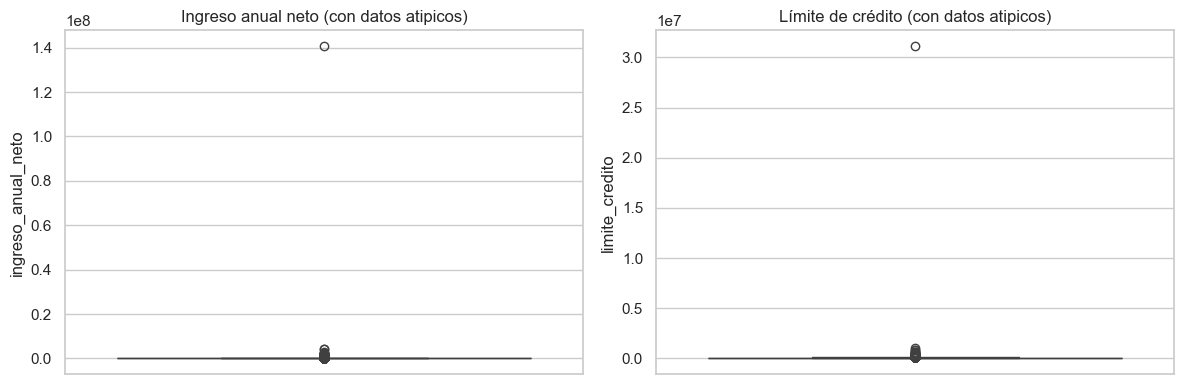

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df['ingreso_anual_neto'], ax=axes[0], color='#1565C0')
axes[0].set_title('Ingreso anual neto (con datos atipicos)')
sns.boxplot(y=df['limite_credito'], ax=axes[1], color='#1565C0')
axes[1].set_title('Límite de crédito (con datos atipicos)')
plt.tight_layout()
plt.show()


## 4. Preprocesamiento de datos
### se elimina incumplimiento_ultimos_6_meses ya que se observo que el 100% de si corresponde a la variable objetivo.

In [19]:
#creamos un dataframe sin columnas id cliente nombre incumplimiento por el caso  descrito arriba. 
df_model = df.drop(columns=['id_cliente', 'nombre', 'incumplimiento_ultimos_6_meses']).copy()

# se usa el percentil 99 para  no eliminar los datos atipicos sino que reducirlos para que entren en la muestra
for col in ['ingreso_anual_neto', 'limite_credito']:
    p99 = df_model[col].quantile(0.99)
    n_afectados = (df_model[col] > p99).sum()
    df_model[col] = np.where(df_model[col] > p99, p99, df_model[col])
    print(f"{col}: {n_afectados} valores recortados al percentil 99 ({p99:,.2f})")


df_model['target'] = (df_model['incumplimiento_tarjeta_credito'] == 'Sí').astype(int)
df_model = df_model.drop(columns=['incumplimiento_tarjeta_credito'])

df_model.head()


ingreso_anual_neto: 456 valores recortados al percentil 99 (577,901.51)
limite_credito: 456 valores recortados al percentil 99 (145,102.30)


,edad,genero,tiene_auto,tiene_casa,numero_hijos,ingreso_anual_neto,dias_empleado,tipo_ocupacion,total_miembros_familia,trabajador_migrante,pagos_anuales_deuda,limite_credito,porcentaje_limite_credito_utilizado,puntaje_crediticio,incumplimientos_previos,target
0,46,Femenino,No,Sí,0,107934.04,612,Desconocido,1,Sí,33070.28,18690.93,73,544,2,1
1,29,Masculino,No,Sí,0,109862.62,2771,Obreros,2,No,15329.53,37745.19,52,857,0,0
2,37,Masculino,No,Sí,0,230153.17,204,Obreros,2,No,48416.60,41598.36,43,650,0,0
3,39,Femenino,No,Sí,0,122325.82,11941,Personal administrativo,2,No,22574.36,32627.76,20,754,0,0
4,46,Masculino,Sí,Sí,0,387286.00,1459,Personal administrativo,1,No,38282.95,52950.64,75,927,0,0


In [20]:

X = df_model.drop(columns=['target'])
y = df_model['target']

categorical_features = ['genero', 'tiene_auto', 'tiene_casa', 'tipo_ocupacion', 'trabajador_migrante']
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Features numéricas:", numeric_features)
print("Features categóricas:", categorical_features)

# Codificación One-Hot solo para las columnas categóricas; las numéricas pasan sin cambios
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), categorical_features)
    ],
    remainder='passthrough'  # deja pasar las numéricas tal cual (árboles no necesitan escalado)
)


Features numéricas: ['edad', 'numero_hijos', 'ingreso_anual_neto', 'dias_empleado', 'total_miembros_familia', 'pagos_anuales_deuda', 'limite_credito', 'porcentaje_limite_credito_utilizado', 'puntaje_crediticio', 'incumplimientos_previos']
Features categóricas: ['genero', 'tiene_auto', 'tiene_casa', 'tipo_ocupacion', 'trabajador_migrante']


In [21]:

# División train/test estratificada (70/30) para preservar la proporción 92%/8% en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.30, 
    random_state=RANDOM_STATE, 
    stratify=y
)

print(f"entreno: {X_train.shape[0]} filas | Tasa de incumplimiento: {y_train.mean()*100:.2f}%")
print(f"prueba:  {X_test.shape[0]} filas | Tasa de incumplimiento: {y_test.mean()*100:.2f}%")


entreno: 31869 filas | Tasa de incumplimiento: 8.12%
prueba:  13659 filas | Tasa de incumplimiento: 8.12%


## 5. Modelado: Random Forest

Entrenamos un **Random Forest**: ensamble de árboles independientes entrenados por *bagging*
(muestreo con reemplazo) y selección aleatoria de variables en cada split. Es robusto a outliers y ruido,
maneja bien variables mixtas (numéricas + categóricas) y relaciones no lineales, y es menos propenso a
sobreajuste que un árbol individual.

Se integra en un `Pipeline` de sklearn junto con el `preprocessor` (One-Hot Encoding), para evitar
*data leakage* entre train y test durante el preprocesamiento. El desbalance de clases (~8%) se compensa
con `class_weight='balanced'`.

### 5.1 Entrenamiento del Random Forest

In [22]:

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=10,             # limita profundidad para reducir sobreajuste
        min_samples_leaf=20,      # evita ruido
        class_weight='balanced',  
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

y_pred_rf = rf_pipeline.predict(X_test)
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print("=== Random Forest - Reporte de clasificación (umbral 0.5) ===")
print(classification_report(y_test, y_pred_rf, target_names=['No incumple', 'Incumple']))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_rf):.4f}")
print(f"AUC-PR : {average_precision_score(y_test, y_proba_rf):.4f}")


=== Random Forest - Reporte de clasificación (umbral 0.5) ===
              precision    recall  f1-score   support

 No incumple       1.00      0.95      0.97     12550
    Incumple       0.63      1.00      0.77      1109

    accuracy                           0.95     13659
   macro avg       0.81      0.97      0.87     13659
weighted avg       0.97      0.95      0.96     13659

AUC-ROC: 0.9948
AUC-PR : 0.9523


### 5.2 Ajuste del umbral de decisión


=== Simulación de Umbrales Alternativos ===
Umbral: 0.50 -> Precisión: 0.63 | Recall: 1.00 | F1-Score: 0.77
Umbral: 0.55 -> Precisión: 0.63 | Recall: 0.99 | F1-Score: 0.77
Umbral: 0.60 -> Precisión: 0.64 | Recall: 0.98 | F1-Score: 0.78
Umbral: 0.65 -> Precisión: 0.70 | Recall: 0.96 | F1-Score: 0.81
Umbral: 0.70 -> Precisión: 0.77 | Recall: 0.91 | F1-Score: 0.83
Umbral: 0.75 -> Precisión: 0.86 | Recall: 0.84 | F1-Score: 0.85
Umbral: 0.80 -> Precisión: 0.96 | Recall: 0.76 | F1-Score: 0.85


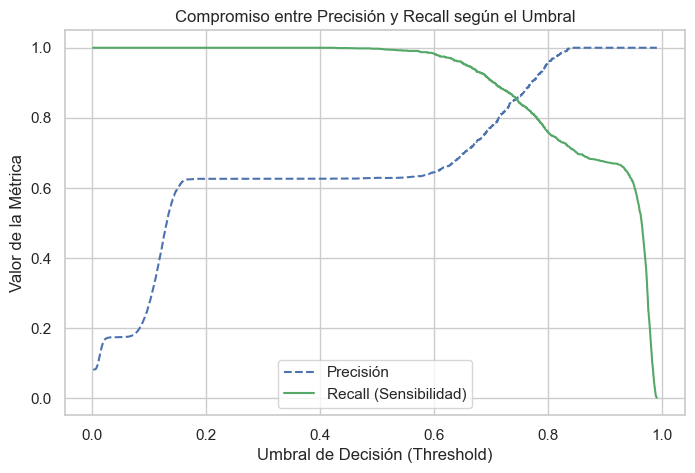

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, classification_report


# 1. EVALUAR EL IMPACTO DE UMBRAL

print("\n=== Simulación de Umbrales Alternativos ===")
# Probamos diferentes umbrales desde 0.50 hasta 0.80
for umbral in [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]:
    # Clasifica como 'Incumple' (1) solo si supera el umbral
    y_pred_personalizado = (y_proba_rf >= umbral).astype(int)
    
    # Extraemos métricas para la clase 'Incumple' (clase 1)
    reporte = classification_report(y_test, y_pred_personalizado, output_dict=True)
    precision_1 = reporte['1']['precision']
    recall_1 = reporte['1']['recall']
    f1_1 = reporte['1']['f1-score']
    
    print(f"Umbral: {umbral:.2f} -> Precisión: {precision_1:.2f} | Recall: {recall_1:.2f} | F1-Score: {f1_1:.2f}")

# ==========================================
# 2. GRAFICAR LA CURVA PRECISIÓN-RECALL (PR)
# ==========================================
precisiones, recalls, umbrales = precision_recall_curve(y_test, y_proba_rf)

plt.figure(figsize=(8, 5))
plt.plot(umbrales, precisiones[:-1], 'b--', label='Precisión')
plt.plot(umbrales, recalls[:-1], 'g-', label='Recall (Sensibilidad)')
plt.xlabel('Umbral de Decisión (Threshold)')
plt.ylabel('Valor de la Métrica')
plt.title('Compromiso entre Precisión y Recall según el Umbral')
plt.grid(True)
plt.legend(loc='best')
plt.show()


In [25]:
# 1. Definimos el nuevo umbral seleccionado
UMBRAL_ELEGIDO = 0.75

# 2. Convertimos las probabilidades en clases binarias usando el nuevo umbral
y_pred_final = (y_proba_rf >= UMBRAL_ELEGIDO).astype(int)

# 3. Imprimimos el reporte final corregido
print(f"=== Random Forest - Reporte de Clasificación (Umbral definitivo: {UMBRAL_ELEGIDO}) ===")
print(classification_report(y_test, y_pred_final, target_names=['No incumple', 'Incumple']))


=== Random Forest - Reporte de Clasificación (Umbral definitivo: 0.75) ===
              precision    recall  f1-score   support

 No incumple       0.99      0.99      0.99     12550
    Incumple       0.86      0.84      0.85      1109

    accuracy                           0.98     13659
   macro avg       0.92      0.92      0.92     13659
weighted avg       0.98      0.98      0.98     13659



## 6. Evaluación del modelo Random Forest

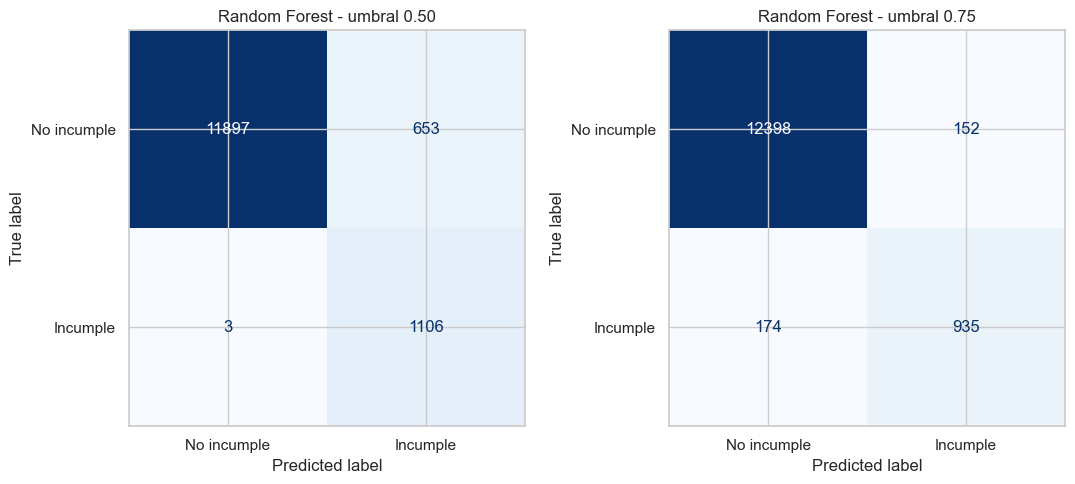

In [26]:
# Matrices de confusión del mismo modelo: umbral por defecto (0.5) vs. umbral elegido
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=['No incumple', 'Incumple'],
                                         cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Random Forest - umbral 0.50')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, display_labels=['No incumple', 'Incumple'],
                                         cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title(f'Random Forest - umbral {UMBRAL_ELEGIDO}')
plt.tight_layout()
plt.show()

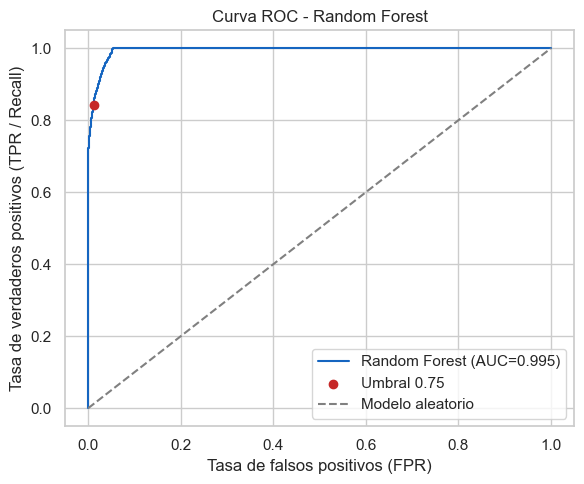

In [27]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

# Punto de operación del umbral elegido
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_final).ravel()

plt.figure(figsize=(6, 5))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC={roc_auc_score(y_test, y_proba_rf):.3f})', color='#1565C0')
plt.scatter(fp / (fp + tn), tp / (tp + fn), color='#C62828', zorder=5, label=f'Umbral {UMBRAL_ELEGIDO}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Modelo aleatorio')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR / Recall)')
plt.title('Curva ROC - Random Forest')
plt.legend()
plt.tight_layout()
plt.show()

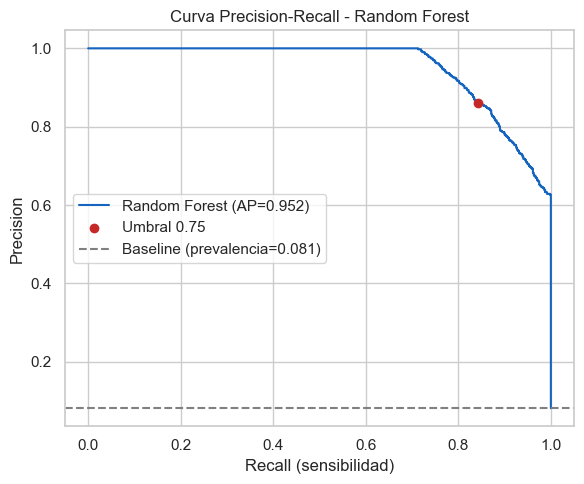

In [28]:
prec_rf, rec_rf, _ = precision_recall_curve(y_test, y_proba_rf)
baseline = y_test.mean()

plt.figure(figsize=(6, 5))
plt.plot(rec_rf, prec_rf, label=f'Random Forest (AP={average_precision_score(y_test, y_proba_rf):.3f})', color='#1565C0')
plt.scatter(recall_score(y_test, y_pred_final), precision_score(y_test, y_pred_final),
            color='#C62828', zorder=5, label=f'Umbral {UMBRAL_ELEGIDO}')
plt.axhline(baseline, linestyle='--', color='gray', label=f'Baseline (prevalencia={baseline:.3f})')
plt.xlabel('Recall (sensibilidad)')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall - Random Forest')
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
# Resumen de métricas del Random Forest (clase "Incumple")
resumen = pd.DataFrame({
    'Métrica': ['AUC-ROC', 'AUC-PR', 'Precision', 'Recall', 'F1'],
    'Umbral 0.50': [roc_auc_score(y_test, y_proba_rf), average_precision_score(y_test, y_proba_rf),
                    precision_score(y_test, y_pred_rf), recall_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf)],
    f'Umbral {UMBRAL_ELEGIDO}': [roc_auc_score(y_test, y_proba_rf), average_precision_score(y_test, y_proba_rf),
                    precision_score(y_test, y_pred_final), recall_score(y_test, y_pred_final), f1_score(y_test, y_pred_final)],
}).round(4)
resumen

,Métrica,Umbral 0.50,Umbral 0.75
0,AUC-ROC,0.9948,0.9948
1,AUC-PR,0.9523,0.9523
2,Precision,0.6288,0.8602
3,Recall,0.9973,0.8431
4,F1,0.7713,0.8515


## 7. Umbral de decisión y modelo final

**Criterio:** el objetivo de negocio es *priorizar la detección de clientes riesgosos* (minimizar falsos
negativos) sin generar demasiadas alertas falsas que afecten a los buenos clientes. Por eso se miran
**AUC-PR**, **Recall** y **Precision** de la clase "Incumple" y no el accuracy.

Con `class_weight='balanced'` las probabilidades del modelo quedan infladas para la clase minoritaria, así que
el umbral 0.5 no es neutral: detecta casi todos los incumplimientos (recall ≈ 1.00) pero con precision ≈ 0.63, es decir,
~37% de las alertas son falsas. Al subir el umbral:

- **0.70:** precision 0.77 / recall 0.91 / F1 0.83
- **0.75:** precision 0.86 / recall 0.84 / F1 0.85 → **umbral elegido**, mejor equilibrio entre ambas métricas
- **0.80:** precision 0.96 / recall 0.76 / F1 0.85 → más conservador, pero se escapan más morosos

> **Limitación:** el umbral se eligió observando el conjunto de prueba, por lo que las métricas finales pueden ser
> ligeramente optimistas. Lo ideal es elegirlo en un conjunto de validación (o con validación cruzada) y dejar el
> test solo para la medición final.

In [30]:
# Modelo final: Random Forest con el umbral elegido en la sección 5.2
modelo_final = rf_pipeline
nombre_modelo_final = 'Random Forest'
y_proba_final = y_proba_rf
y_pred_final = (y_proba_final >= UMBRAL_ELEGIDO).astype(int)

print(f"Modelo final: {nombre_modelo_final} | Umbral: {UMBRAL_ELEGIDO}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_final):.4f} | AUC-PR: {average_precision_score(y_test, y_proba_final):.4f}")

Modelo final: Random Forest | Umbral: 0.75
AUC-ROC: 0.9948 | AUC-PR: 0.9523


## 8. Explicabilidad del modelo con SHAP

**¿Por qué SHAP?** SHAP (SHapley Additive exPlanations) asigna a cada variable, para cada
predicción individual, una contribución (positiva o negativa) al resultado del modelo, basada en
teoría de juegos cooperativos (valores de Shapley). Esto permite:

- Entender **qué variables más influyen globalmente** en la predicción de incumplimiento
  (importancia global).
- Explicar **una predicción individual** ("¿por qué el modelo predijo que este cliente específico
  incumplirá?"), algo exigido en muchos marcos regulatorios de crédito (explicabilidad ante el
  cliente y el regulador).

Usamos `TreeExplainer`, optimizado para modelos de árboles como el Random Forest.

In [31]:
clf_final = modelo_final.named_steps['classifier']
X_test_transformed = modelo_final.named_steps['preprocessor'].transform(X_test)
if hasattr(X_test_transformed, "toarray"):      # por si el transformador devuelve matriz dispersa
    X_test_transformed = X_test_transformed.toarray()

feature_names = modelo_final.named_steps['preprocessor'].get_feature_names_out()
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names, index=X_test.index)

explainer = shap.TreeExplainer(clf_final)
shap_values = explainer.shap_values(X_test_df)

# Para Random Forest binario, según la versión de SHAP, el resultado puede ser:
#   - una lista [clase0, clase1]                -> tomamos la clase 1
#   - un arreglo 3D (n_muestras, n_features, 2) -> tomamos [:, :, 1]
#   - un arreglo 2D                             -> se usa tal cual
if isinstance(shap_values, list):
    shap_values_plot = shap_values[1]
else:
    shap_values_plot = np.array(shap_values)
    if shap_values_plot.ndim == 3:
        shap_values_plot = shap_values_plot[:, :, 1]

print("SHAP values calculados. Shape:", shap_values_plot.shape)

SHAP values calculados. Shape: (13659, 37)


### 8.1 Importancia global de variables

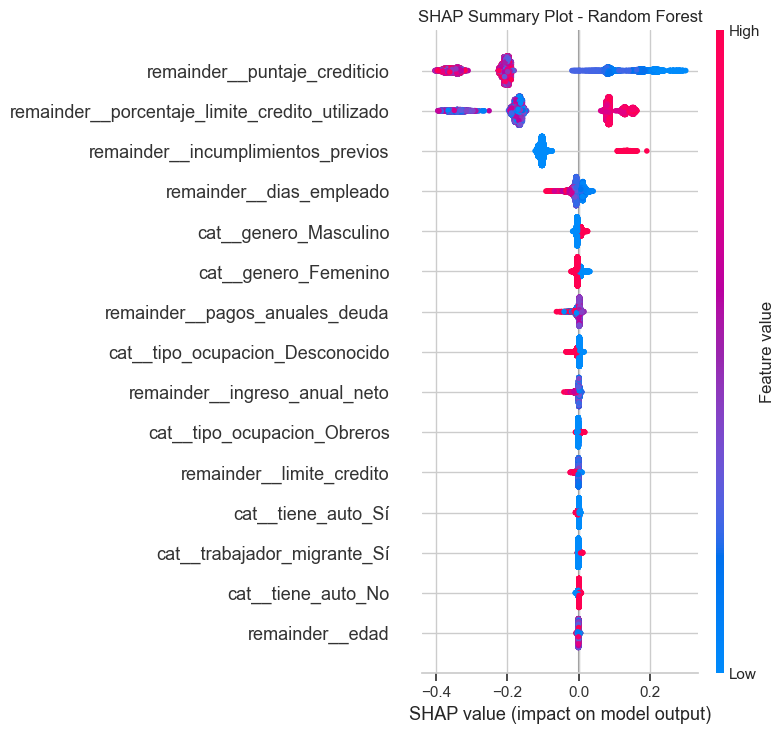

In [32]:

plt.figure()
shap.summary_plot(shap_values_plot, X_test_df, show=False, max_display=15)
plt.title(f"SHAP Summary Plot - {nombre_modelo_final}")
plt.tight_layout()
plt.show()


**Cómo leer este gráfico:** cada punto es un cliente del set de prueba. El eje X es el
impacto SHAP (positivo = empuja la predicción hacia "incumple", negativo = empuja hacia "no
incumple"). El color indica el valor de la variable (rojo = alto, azul = bajo). Por ejemplo, si
`porcentaje_limite_credito_utilizado` muestra puntos rojos a la derecha, significa que un uso alto
del límite de crédito aumenta la probabilidad predicha de incumplimiento — coherente con la
intuición de riesgo crediticio.

### 8.2 Importancia global promedio (barras)

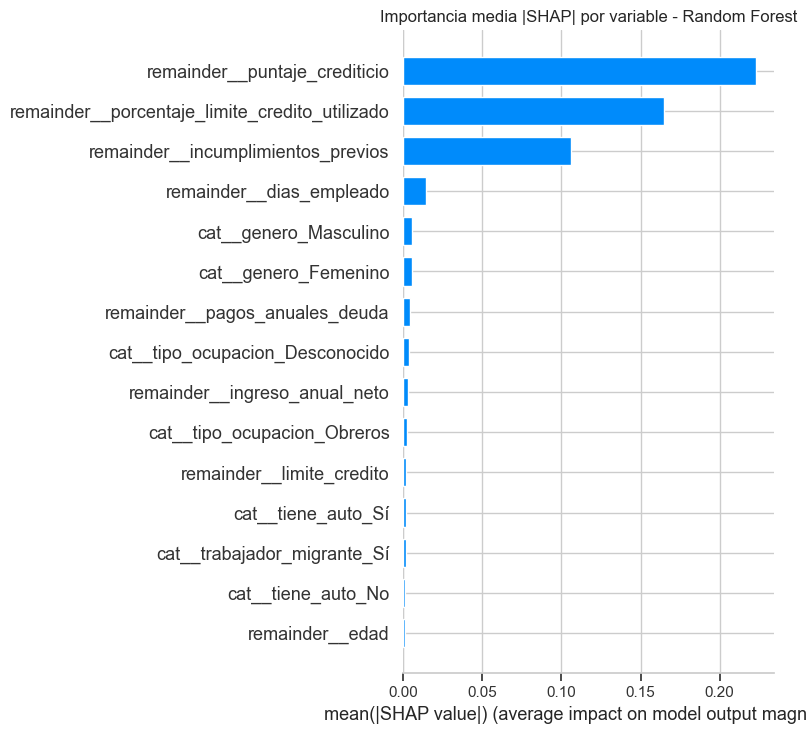

In [33]:

plt.figure()
shap.summary_plot(shap_values_plot, X_test_df, plot_type='bar', show=False, max_display=15)
plt.title(f"Importancia media |SHAP| por variable - {nombre_modelo_final}")
plt.tight_layout()
plt.show()


## 9. Análisis de sesgos algorítmicos (Fairness)

En un modelo de scoring crediticio es fundamental verificar que el modelo **no discrimine
de forma desproporcionada** a grupos protegidos (género, condición migratoria, edad), más allá de
lo que justifica el riesgo real. Calculamos, por subgrupo:

- **Tasa de predicción positiva** (a cuántos se les predice "incumple", i.e. tasa de rechazo/alerta).
- **Recall** (sensibilidad): de los que sí incumplieron, ¿a cuántos detecta el modelo?
- **FPR (False Positive Rate)**: de los buenos pagadores, ¿a cuántos etiqueta erróneamente como
  riesgosos? Un FPR mucho más alto en un grupo protegido es una señal de sesgo (ese grupo sufre
  más rechazos injustos).

Esto no prueba ausencia de sesgo de forma definitiva (requeriría análisis causal y legal más
profundo), pero es un primer diagnóstico cuantitativo estándar en *fairness in ML*.

> Las predicciones evaluadas aquí son las del Random Forest con el umbral elegido (`y_pred_final`).

In [34]:

def metricas_por_grupo(y_true, y_pred, y_proba, grupo, nombre_grupo):
    filas = []
    for valor in grupo.unique():
        mask = (grupo == valor)
        if mask.sum() < 20:  # ignoramos subgrupos con muestra insuficiente para ser confiables
            continue
        yt, yp = y_true[mask], y_pred[mask]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        filas.append({
            nombre_grupo: valor,
            'n': mask.sum(),
            'tasa_incumplimiento_real': yt.mean(),
            'tasa_prediccion_positiva': yp.mean(),
            'recall (TPR)': tp / (tp + fn) if (tp + fn) > 0 else np.nan,
            'FPR': fp / (fp + tn) if (fp + tn) > 0 else np.nan,
        })
    return pd.DataFrame(filas).round(3)

y_test_arr = y_test.reset_index(drop=True)
y_pred_arr = pd.Series(y_pred_final).reset_index(drop=True)
y_proba_arr = pd.Series(y_proba_final).reset_index(drop=True)
grupo_genero = X_test['genero'].reset_index(drop=True)
grupo_migrante = X_test['trabajador_migrante'].reset_index(drop=True)

print("=== Fairness por GÉNERO ===")
tabla_genero = metricas_por_grupo(y_test_arr, y_pred_arr, y_proba_arr, grupo_genero, 'genero')
display(tabla_genero)

print("\n=== Fairness por TRABAJADOR MIGRANTE ===")
tabla_migrante = metricas_por_grupo(y_test_arr, y_pred_arr, y_proba_arr, grupo_migrante, 'trabajador_migrante')
display(tabla_migrante)


=== Fairness por GÉNERO ===


,genero,n,tasa_incumplimiento_real,tasa_prediccion_positiva,recall (TPR),FPR
0,Femenino,9024,0.072,0.065,0.816,0.007
1,Masculino,4635,0.100,0.108,0.881,0.022



=== Fairness por TRABAJADOR MIGRANTE ===


,trabajador_migrante,n,tasa_incumplimiento_real,tasa_prediccion_positiva,recall (TPR),FPR
0,No,11257,0.079,0.077,0.846,0.011
1,Sí,2402,0.090,0.091,0.829,0.018


=== Fairness por GRUPO DE EDAD ===


,grupo_edad,n,tasa_incumplimiento_real,tasa_prediccion_positiva,recall (TPR),FPR
0,46-55,4137,0.080,0.075,0.833,0.010
1,36-45,4058,0.079,0.080,0.856,0.014
2,26-35,4209,0.085,0.085,0.849,0.014
3,<=25,1255,0.080,0.074,0.812,0.010


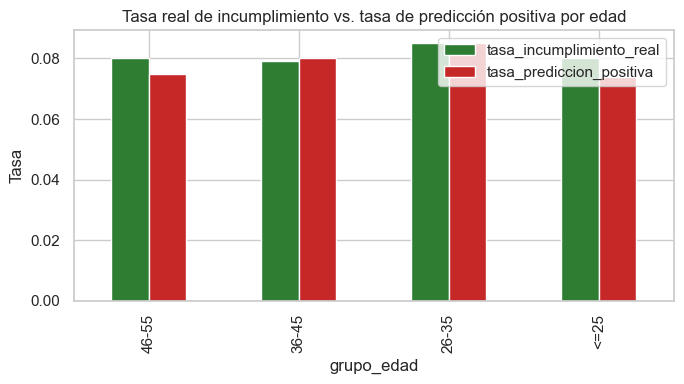

In [35]:

# Fairness por grupo de edad (creamos bins para tener grupos interpretables)
edad_bins = pd.cut(X_test['edad'].reset_index(drop=True),
                    bins=[0, 25, 35, 45, 55, 100],
                    labels=['<=25', '26-35', '36-45', '46-55', '55+'])

print("=== Fairness por GRUPO DE EDAD ===")
tabla_edad = metricas_por_grupo(y_test_arr, y_pred_arr, y_proba_arr, edad_bins, 'grupo_edad')
display(tabla_edad)

fig, ax = plt.subplots(figsize=(7, 4))
tabla_edad.set_index('grupo_edad')[['tasa_incumplimiento_real', 'tasa_prediccion_positiva']].plot(
    kind='bar', ax=ax, color=['#2E7D32', '#C62828']
)
ax.set_ylabel('Tasa')
ax.set_title('Tasa real de incumplimiento vs. tasa de predicción positiva por edad')
plt.tight_layout()
plt.show()


**Interpretación:** si la `tasa_prediccion_positiva` o el `FPR` de un subgrupo (por ejemplo,
`trabajador_migrante = 'Sí'`) es notablemente más alta que la de otros grupos **incluso después de
controlar por el riesgo real** (`tasa_incumplimiento_real`), es una señal de alerta de sesgo
algorítmico que ameritaría: (a) revisar si variables proxy (ocupación, ingreso) están capturando
indirectamente el atributo protegido, (b) aplicar técnicas de *fairness-aware ML* (reweighing,
umbrales por grupo, regularización de equidad), y (c) validación con el equipo legal/compliance
del banco antes de poner el modelo en producción.

Este notebook deja la infraestructura de medición lista; la decisión de mitigación específica
depende de la política de riesgo y el marco regulatorio del banco.

## 10. Conclusiones y recomendaciones

In [36]:
resumen_texto = f'''
RESUMEN EJECUTIVO
------------------
- Problema: prediccion de incumplimiento de pago de tarjeta de credito (scoring crediticio).
- Dataset: {df.shape[0]} clientes, {df.shape[1]} variables originales.
- Hallazgo: se detecto y removio una variable con data leakage
  ('incumplimiento_ultimos_6_meses').
- Modelo: {nombre_modelo_final} (300 arboles, max_depth=10, min_samples_leaf=20, class_weight='balanced').
- AUC-ROC: {roc_auc_score(y_test, y_proba_final):.4f} | AUC-PR: {average_precision_score(y_test, y_proba_final):.4f}
- Umbral de decision: {UMBRAL_ELEGIDO} -> Precision: {precision_score(y_test, y_pred_final):.2f} | Recall: {recall_score(y_test, y_pred_final):.2f} | F1: {f1_score(y_test, y_pred_final):.2f}
- Se genero explicabilidad global con SHAP (TreeExplainer).
- Se evaluo equidad del modelo por genero, condicion migratoria y edad.
'''
print(resumen_texto)


RESUMEN EJECUTIVO
------------------
- Problema: prediccion de incumplimiento de pago de tarjeta de credito (scoring crediticio).
- Dataset: 45528 clientes, 19 variables originales.
- Hallazgo: se detecto y removio una variable con data leakage
  ('incumplimiento_ultimos_6_meses').
- Modelo: Random Forest (300 arboles, max_depth=10, min_samples_leaf=20, class_weight='balanced').
- AUC-ROC: 0.9948 | AUC-PR: 0.9523
- Umbral de decision: 0.75 -> Precision: 0.86 | Recall: 0.84 | F1: 0.85
- Se genero explicabilidad global con SHAP (TreeExplainer).
- Se evaluo equidad del modelo por genero, condicion migratoria y edad.



**Recomendaciones para producción:**
1. Reentrenar periódicamente el modelo con datos recientes (el comportamiento crediticio cambia
   con el ciclo económico).
2. Definir un **umbral de decisión** de negocio (no necesariamente 0.5) según el costo relativo de
   falsos positivos (rechazar a un buen cliente) vs. falsos negativos (aprobar a un mal pagador),
   apoyándose en la curva Precision-Recall de la sección 6.
3. Monitorear el modelo en producción con métricas de *drift* y de *fairness* de forma continua,
   no solo en el momento del entrenamiento.
4. Incorporar las explicaciones SHAP individuales en el flujo de atención al cliente, para poder
   justificar decisiones de crédito de forma transparente.
5. Antes de desplegar, validar los hallazgos de la sección 9 con el equipo de cumplimiento
   normativo del banco.


In [37]:
import joblib

# 1. Definimos el umbral óptimo que encontramos en las simulaciones
UMBRAL_PRODUCCION = 0.75

# 2. Creamos un diccionario (artefacto) que empaqueta todo lo necesario
artefacto_final = {
    'modelo': modelo_final,              # Pipeline del Random Forest
    'nombre_modelo': nombre_modelo_final, # Nombre del modelo en texto
    'umbral': UMBRAL_PRODUCCION          # Guarda el umbral de decisión corregido
}

# 3. Guardamos el archivo en tu disco
nombre_archivo = 'modelo_incumplimiento_final.joblib'
joblib.dump(artefacto_final, nombre_archivo)

print(f"¡Éxito! El modelo {nombre_modelo_final} y su umbral ({UMBRAL_PRODUCCION}) han sido guardados en '{nombre_archivo}'")


¡Éxito! El modelo Random Forest y su umbral (0.75) han sido guardados en 'modelo_incumplimiento_final.joblib'


## esto es la simulacion hay que crear otro notebook

In [ ]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# 1. CARGAR EL MODELO DESDE EL ARTEFACTO JOBLIB
# =====================================================================
artefacto = joblib.load('modelo_incumplimiento_final.joblib')
pipeline = artefacto['modelo']
nombre_modelo = artefacto['nombre_modelo']
print(f"-> Cargado exitosamente el modelo: {nombre_modelo}")

# =====================================================================
# 2. PORTAFOLIO DE PRUEBA (clientes reales del set de prueba)
# =====================================================================
X_portafolio = X_test.copy()
num_clientes = len(X_portafolio)
print(f"Cargados {num_clientes:,} clientes reales para la simulación.")

# Exposición al incumplimiento (EAD): límite de crédito real de cada cliente
exposicion_por_cliente = X_portafolio['limite_credito'].values
# Severidad / pérdida dado el incumplimiento (LGD): 45% estándar para consumo
severidad_por_cliente = 0.45

# =====================================================================
# 3. PROBABILIDADES DE INCUMPLIMIENTO (PD) CON EL MODELO
# =====================================================================
pd_individuales = pipeline.predict_proba(X_portafolio)[:, 1]
print(f"Probabilidades calculadas con {nombre_modelo}.")

# =====================================================================
# 4. SIMULACIÓN DE MONTECARLO (10,000 escenarios)
# =====================================================================
rng = np.random.default_rng(RANDOM_STATE)
num_simulaciones = 10000
perdidas_totales_escenarios = np.zeros(num_simulaciones)
perdida_por_cliente_si_incumple = exposicion_por_cliente * severidad_por_cliente

print(f"Ejecutando {num_simulaciones:,} simulaciones de Montecarlo...")
for i in range(num_simulaciones):
    # Bernoulli: el cliente incumple si el número aleatorio es <= su PD
    incumplimientos_simulados = rng.random(num_clientes) <= pd_individuales
    perdidas_totales_escenarios[i] = (incumplimientos_simulados * perdida_por_cliente_si_incumple).sum()

# =====================================================================
# 5. MÉTRICAS FINANCIERAS DE RIESGO
# =====================================================================
perdida_esperada = np.mean(perdidas_totales_escenarios)
var_95 = np.percentile(perdidas_totales_escenarios, 95)
var_99 = np.percentile(perdidas_totales_escenarios, 99)

# Referencia: pérdida que realmente ocurrió en el set de prueba
perdida_real_observada = (y_test.values * perdida_por_cliente_si_incumple).sum()

print("\n================ RESULTADOS DE RIESGO ================")
print(f"Pérdida Promedio Esperada (EL)  : ${perdida_esperada:,.2f}")
print(f"Valor en Riesgo al 95% (VaR 95%): ${var_95:,.2f}")
print(f"Valor en Riesgo al 99% (VaR 99%): ${var_99:,.2f}")
print(f"Pérdida real observada (test)   : ${perdida_real_observada:,.2f}")
print("======================================================")

# =====================================================================
# 6. DISTRIBUCIÓN DE PÉRDIDAS
# =====================================================================
plt.figure(figsize=(10, 6))
plt.hist(perdidas_totales_escenarios, bins=50, color='darkblue', edgecolor='black', alpha=0.7)
plt.axvline(perdida_esperada, color='green', linestyle='--', linewidth=2, label=f'Pérdida Esperada (${perdida_esperada:,.0f})')
plt.axvline(var_95, color='orange', linestyle='--', linewidth=2, label=f'VaR 95% (${var_95:,.0f})')
plt.axvline(var_99, color='red', linestyle='--', linewidth=2, label=f'VaR 99% (${var_99:,.0f})')
plt.axvline(perdida_real_observada, color='black', linestyle=':', linewidth=2, label=f'Pérdida real (${perdida_real_observada:,.0f})')
plt.title('Simulación de Montecarlo: Distribución de Pérdidas de la Cartera')
plt.xlabel('Pérdida Total ($)')
plt.ylabel('Frecuencia (Escenarios)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

artefacto_final = {
    'modelo': modelo_final,
    'nombre_modelo': nombre_modelo_final,
    'umbral': 0.75
}

# Guarda con la ruta absoluta donde tienes tu app.py
ruta_guardado = r"C:\Users\ramonroy\desktop\rm\avancesproyecto_ia\modelo_incumplimiento_final.joblib"
joblib.dump(artefacto_final, ruta_guardado)

print(f"¡Modelo guardado con éxito en: {ruta_guardado}!")
